/Users/hwangdayoung/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


Epoch 1/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/step - accuracy: 0.5077 - loss: 0.6931 - val_accuracy: 0.5286 - val_loss: 0.6928
Epoch 2/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - accuracy: 0.5366 - loss: 0.6925 - val_accuracy: 0.5776 - val_loss: 0.6918
Epoch 3/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.5760 - loss: 0.6910 - val_accuracy: 0.6322 - val_loss: 0.6879
Epoch 4/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - accuracy: 0.6169 - loss: 0.6840 - val_accuracy: 0.6794 - val_loss: 0.6610
Epoch 5/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step - accuracy: 0.6704 - loss: 0.6451 - val_accuracy: 0.7124 - val_loss: 0.5885
Epoch 6/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - accuracy: 0.7106 - loss: 0.5888 - val_accuracy: 0.7352 - val_loss: 0.5565
Epoch 7/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - accuracy: 0.7368 - loss: 0.5596 - val_accuracy: 0.7512 - val_loss: 0.5349
Epoch 8/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.7513 - loss: 0.5385 - 

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 100, 16)        │         8,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 100, 8)         │           800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 8)              │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,708 (73.08 KB)

 Trainable params: 9,353 (36.54 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 9,355 (36.55 KB)

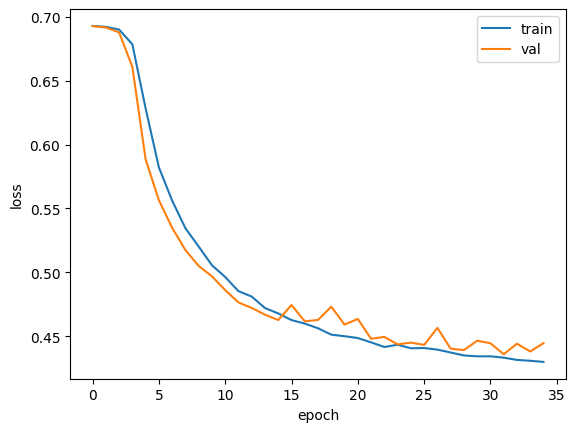

782/782 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8011 - loss: 0.4305
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step
Predict Probability =  [[0.8676567]]
Label for new data =  [1]


In [1]:
import numpy as np
import tensorflow as tf
import keras
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from keras.datasets import imdb
from keras.preprocessing.sequence import pad_sequences

(train_input, train_target), (test_input, test_target) = imdb.load_data(num_words=500)
train_input, val_input, train_target, val_target = train_test_split(train_input, train_target, test_size=0.2, random_state=42)

Seq_length = 100
train_seq = pad_sequences(train_input, maxlen=Seq_length)
val_seq = pad_sequences(val_input, maxlen=Seq_length)
test_seq = pad_sequences(test_input, maxlen=Seq_length)

num_voca = 500
dim_word = 16
dim_hidden = 8

model = keras.Sequential()
model.add(keras.layers.Embedding(num_voca, dim_word))
model.add(keras.layers.LSTM(dim_hidden, dropout=0.3, return_sequences=True))
model.add(keras.layers.LSTM(dim_hidden, dropout=0.3))
model.add(keras.layers.Dense(1, activation='sigmoid'))

rmsprop = keras.optimizers.RMSprop(learning_rate=1e-4)
model.compile(optimizer=rmsprop, loss='binary_crossentropy', metrics=['accuracy'])
cp = keras.callbacks.ModelCheckpoint('IMDB-LSTM-model.keras', save_best_only=True)
es = keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True)
history = model.fit(train_seq, train_target, epochs=100, batch_size=64, validation_data=(val_seq, val_target), callbacks=[cp, es])
model.summary()

plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.xlabel('epoch')
plt.ylabel('loss')
plt.legend(['train', 'val'])
plt.show()

model.evaluate(test_seq, test_target)

i = 65
new_data = test_seq[i:i+1]
print('Predict Probability = ', model.predict(new_data))
print('Label for new data = ', test_target[i:i+1])

Epoch 1/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.4990 - loss: 0.6932 - val_accuracy: 0.4970 - val_loss: 0.6930
Epoch 2/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.5196 - loss: 0.6926 - val_accuracy: 0.6076 - val_loss: 0.6919
Epoch 3/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.5705 - loss: 0.6911 - val_accuracy: 0.6438 - val_loss: 0.6873
Epoch 4/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.6022 - loss: 0.6836 - val_accuracy: 0.6532 - val_loss: 0.6590
Epoch 5/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.6598 - loss: 0.6492 - val_accuracy: 0.6912 - val_loss: 0.6224
Epoch 6/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.6961 - loss: 0.6136 - val_accuracy: 0.7032 - val_loss: 0.5993
Epoch 7/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.7215 - loss: 0.5852 - val_accuracy: 0.7112 - val_loss: 0.5783
Epoch 8/100
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.7255 - loss: 0.5686 - 

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 80, 12)         │         6,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 80, 8)          │           672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 8)              │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,452 (56.46 KB)

 Trainable params: 7,225 (28.22 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 7,227 (28.23 KB)

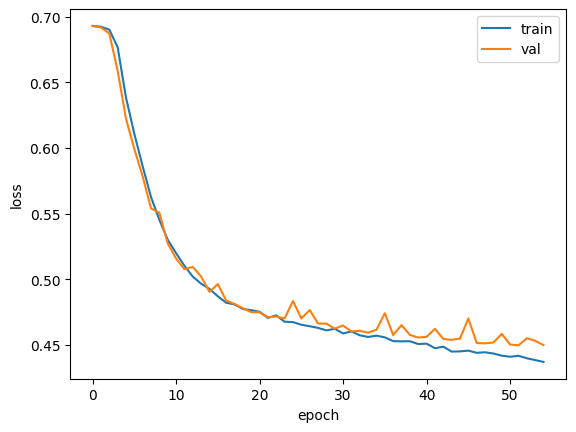

782/782 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7949 - loss: 0.4421
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 111ms/step
Predict Probability =  [[0.7136776]]
Label for new data =  [1]


In [2]:
import numpy as np
import tensorflow as tf
import keras
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from keras.datasets import imdb
from keras.preprocessing.sequence import pad_sequences

(train_input, train_target), (test_input, test_target) = imdb.load_data(num_words=500)
train_input, val_input, train_target, val_target = train_test_split(train_input, train_target, test_size=0.2, random_state=42)

Seq_length = 80
train_seq = pad_sequences(train_input, maxlen=Seq_length)
val_seq = pad_sequences(val_input, maxlen=Seq_length)
test_seq = pad_sequences(test_input, maxlen=Seq_length)

num_voca = 500
dim_word = 12
dim_hidden = 8

model = keras.Sequential()
model.add(keras.layers.Embedding(num_voca, dim_word))
model.add(keras.layers.LSTM(dim_hidden, dropout=0.3, return_sequences=True))
model.add(keras.layers.LSTM(dim_hidden, dropout=0.3))
model.add(keras.layers.Dense(1, activation='sigmoid'))

rmsprop = keras.optimizers.RMSprop(learning_rate=1e-4)
model.compile(optimizer=rmsprop, loss='binary_crossentropy', metrics=['accuracy'])
cp = keras.callbacks.ModelCheckpoint('IMDB-LSTM-model.keras', save_best_only=True)
es = keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True)
history = model.fit(train_seq, train_target, epochs=100, batch_size=64, validation_data=(val_seq, val_target), callbacks=[cp, es])
model.summary()

plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.xlabel('epoch')
plt.ylabel('loss')
plt.legend(['train', 'val'])
plt.show()

model.evaluate(test_seq, test_target)

i = 65
new_data = test_seq[i:i+1]
print('Predict Probability = ', model.predict(new_data))
print('Label for new data = ', test_target[i:i+1])

In [3]:
A = np.array([[1, 2], [3, 4]])
B = np.array([[5, 6], [7, 8]])

print(A)
print(B)

hadamard_product = A * B
print(hadamard_product)

matrix_multiplication = np.dot(A, B)
print(matrix_multiplication)

[[1 2]
 [3 4]]
[[5 6]
 [7 8]]
[[ 5 12]
 [21 32]]
[[19 22]
 [43 50]]


In [4]:
import numpy as np
import matplotlib.pyplot as plt

w = 10.0              # 최적화할 가중치 (예시)
eta = 10.0 # 학습률
decay_rate = 0.9    # 감쇠율 (beta)
v = 0.0            # 기울기의 지수평균
gradient = [1,2,3,4,5,6,7,8,9,8,7,6,5,4,3,2,1]  # 기울기 변화

grads_history = []
v_history = []
etas_history = []
w_history = []

for grad in gradient:
  v = decay_rate * v + (1 - decay_rate) * (grad ** 2)  # 기울기의 지수평균 계산
  eta = eta / np.sqrt(v)     # 학습율 조정
  w = w -  eta * grad                # 매개변수 갱신

  grads_history.append(grad)
  v_history.append(v)
  etas_history.append(eta)
  w_history.append(w)

  result = np.array([w, grad, eta])
  print(result.round(3))

[-21.623   1.     31.623]
[-111.974    2.      45.175]
[-229.007    3.      39.011]
[-322.146    4.      23.285]
[-374.077    5.      10.386]
[-395.941    6.       3.644]
[-403.241    7.       1.043]
[-4.05241e+02  8.00000e+00  2.50000e-01]
[-4.05703e+02  9.00000e+00  5.10000e-02]
[-4.05781e+02  8.00000e+00  1.00000e-02]
[-4.05793e+02  7.00000e+00  2.00000e-03]
[-405.795    6.       0.   ]
[-405.795    5.       0.   ]
[-405.795    4.       0.   ]
[-405.795    3.       0.   ]
[-405.795    2.       0.   ]
[-405.795    1.       0.   ]


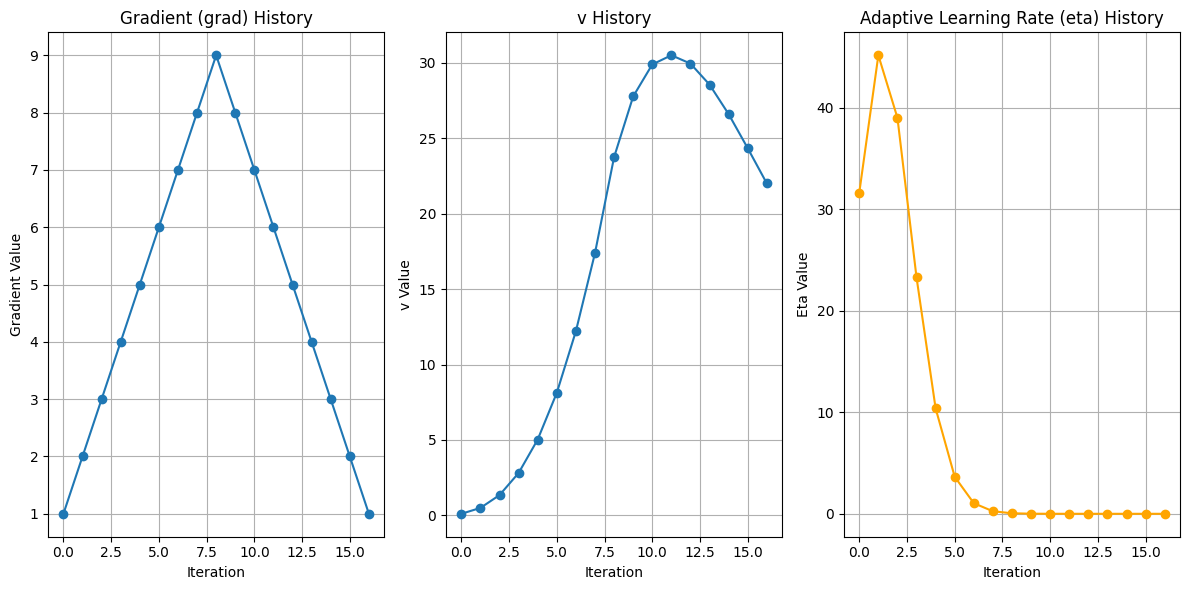

In [5]:
plt.figure(figsize=(12, 6))

plt.subplot(1, 3, 1)
plt.plot(grads_history, marker='o')
plt.title('Gradient (grad) History')
plt.xlabel('Iteration')
plt.ylabel('Gradient Value')
plt.grid(True)

plt.subplot(1, 3, 2)
plt.plot(v_history, marker='o')
plt.title('v History')
plt.xlabel('Iteration')
plt.ylabel('v Value')
plt.grid(True)

plt.subplot(1, 3, 3)
plt.plot(etas_history, marker='o', color='orange')
plt.title('Adaptive Learning Rate (eta) History')
plt.xlabel('Iteration')
plt.ylabel('Eta Value')
plt.grid(True)

plt.tight_layout()
plt.show()

In [6]:
# 문자열 전처리(String) – 단어시퀀스(sentence List) - 어휘 사전(vocabulary Dict) – 아이디시퀀스(corpus Array)
import numpy as np
text1 = 'I say hello you say bye. You like the movie, he like it too.' 
text2 = text1.lower() 
text2 = text2.replace('.', ' .') 
text2 = text2.replace(',', ' ,') 
sentence = text2.split(' ') 

voc_to_id = {}
id_to_voc = {}
for word in sentence:
    if word not in voc_to_id:
        new_id = len(voc_to_id)
        voc_to_id[word] = new_id
        id_to_voc[new_id] = word
  
corpus = np.array([voc_to_id[w] for w in sentence])

print('text1 = ', text1, type(text1))
print('text2 = ', text2, type(text2))
print('sentence = ', sentence, type(sentence))
print('corpus = ', corpus, type(corpus))
print('voc:ID = ', voc_to_id)
print('ID:voc = ', id_to_voc)

text1 =  I say hello you say bye. You like the movie, he like it too. <class 'str'>
text2 =  i say hello you say bye . you like the movie , he like it too . <class 'str'>
sentence =  ['i', 'say', 'hello', 'you', 'say', 'bye', '.', 'you', 'like', 'the', 'movie', ',', 'he', 'like', 'it', 'too', '.'] <class 'list'>
corpus =  [ 0  1  2  3  1  4  5  3  6  7  8  9 10  6 11 12  5] <class 'numpy.ndarray'>
voc:ID =  {'i': 0, 'say': 1, 'hello': 2, 'you': 3, 'bye': 4, '.': 5, 'like': 6, 'the': 7, 'movie': 8, ',': 9, 'he': 10, 'it': 11, 'too': 12}
ID:voc =  {0: 'i', 1: 'say', 2: 'hello', 3: 'you', 4: 'bye', 5: '.', 6: 'like', 7: 'the', 8: 'movie', 9: ',', 10: 'he', 11: 'it', 12: 'too'}


In [10]:
print(sentence)

voc_to_id = {}
id_to_voc = {}

for word in sentence:
    if word not in voc_to_id:
        new_id = len(voc_to_id)
        voc_to_id[word] = new_id
        id_to_voc[new_id] = word

corpus = np.array([voc_to_id[w] for w in sentence])

print('voc_to_id', voc_to_id)
print('id_to_voc', id_to_voc)
print('corpus', corpus)

['i', 'say', 'hello', 'you', 'say', 'bye', '.', 'you', 'like', 'the', 'movie', ',', 'he', 'like', 'it', 'too', '.']
voc_to_id {'i': 0, 'say': 1, 'hello': 2, 'you': 3, 'bye': 4, '.': 5, 'like': 6, 'the': 7, 'movie': 8, ',': 9, 'he': 10, 'it': 11, 'too': 12}
id_to_voc {0: 'i', 1: 'say', 2: 'hello', 3: 'you', 4: 'bye', 5: '.', 6: 'like', 7: 'the', 8: 'movie', 9: ',', 10: 'he', 11: 'it', 12: 'too'}
corpus [ 0  1  2  3  1  4  5  3  6  7  8  9 10  6 11 12  5]
